# AI Group Assignment 2

## Problem 1: Smart Home Energy Consumption Analysis Using Bayesian Networks

### Objective

The objective of this assignment is to construct a Bayesian Network to analyze household energy consumption under uncertainty.

The network models the relationships between weather, day type, occupancy, air-conditioner usage, appliance load, and energy consumption.

The assignment includes probabilistic inference, conditional independence analysis, synthetic data generation, parameter learning, and comparison of expert-defined and learned Bayesian Networks.

### Variables

* **Weather (W):** Hot, Mild, Cold
* **Day Type (D):** Weekday, Weekend
* **Occupancy (O):** High, Low
* **AC Usage (A):** On, Off
* **Appliance Load (L):** Heavy, Light
* **Energy Consumption (E):** High, Low

### Network Structure

The Bayesian Network contains the following dependencies:

* Day Type → Occupancy
* Weather → AC Usage
* Occupancy → AC Usage
* Occupancy → Appliance Load
* AC Usage → Energy Consumption
* Appliance Load → Energy Consumption

Weather and Day Type are independent root nodes in the expert-defined network.


In [1]:
%pip install pgmpy pandas numpy matplotlib networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 8.7 MB/s eta 0:00:00


In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully.")

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Libraries imported successfully.


### Constructing the Expert Bayesian Network

A Bayesian Network is a directed acyclic graph (DAG) in which nodes represent random variables and directed edges represent probabilistic dependencies.

The joint probability distribution can be factorized as:

$$
P(W,D,O,A,L,E)
=
P(W)P(D)P(O\mid D)P(A\mid W,O)P(L\mid O)P(E\mid A,L)
$$

This factorization allows us to calculate the probability of energy consumption by combining the prior probabilities and conditional probability tables.


In [3]:
model = DiscreteBayesianNetwork([
    ("D", "O"),
    ("W", "A"),
    ("O", "A"),
    ("O", "L"),
    ("A", "E"),
    ("L", "E")
])

print("Network nodes:", list(model.nodes()))
print("Network edges:", list(model.edges()))

Network nodes: ['D', 'O', 'W', 'A', 'L', 'E']
Network edges: [('D', 'O'), ('O', 'A'), ('O', 'L'), ('W', 'A'), ('A', 'E'), ('L', 'E')]


In [4]:
cpd_W = TabularCPD(
    variable="W",
    variable_card=3,
    values=[
        [0.50],
        [0.30],
        [0.20]
    ],
    state_names={"W": ["Hot", "Mild", "Cold"]}
)

cpd_D = TabularCPD(
    variable="D",
    variable_card=2,
    values=[
        [0.70],
        [0.30]
    ],
    state_names={"D": ["Weekday", "Weekend"]}
)

cpd_O = TabularCPD(
    variable="O",
    variable_card=2,
    values=[
        [0.45, 0.80],
        [0.55, 0.20]
    ],
    evidence=["D"],
    evidence_card=[2],
    state_names={
        "O": ["High", "Low"],
        "D": ["Weekday", "Weekend"]
    }
)

cpd_A = TabularCPD(
    variable="A",
    variable_card=2,
    values=[
        [0.90, 0.60, 0.40, 0.15, 0.10, 0.05],
        [0.10, 0.40, 0.60, 0.85, 0.90, 0.95]       ],
    evidence=["W", "O"],
    evidence_card=[3, 2],
    state_names={
        "A": ["On", "Off"],
        "W": ["Hot", "Mild", "Cold"],
        "O": ["High", "Low"]
    }
)

cpd_L = TabularCPD(
    variable="L",
    variable_card=2,
    values=[
        [0.75, 0.35],
        [0.25, 0.65]
    ],
    evidence=["O"],
    evidence_card=[2],
    state_names={
        "L": ["Heavy", "Light"],
        "O": ["High", "Low"]
    }
)

cpd_E = TabularCPD(
    variable="E",
    variable_card=2,
    values=[
        [0.92, 0.68, 0.55, 0.12],
        [0.08, 0.32, 0.45, 0.88]
    ],
    evidence=["A", "L"],
    evidence_card=[2, 2],
    state_names={
        "E": ["High", "Low"],
        "A": ["On", "Off"],
        "L": ["Heavy", "Light"]
    }
)

model.add_cpds(cpd_W, cpd_D, cpd_O, cpd_A, cpd_L, cpd_E)

print("Model valid:", model.check_model())

Model valid: True


In [5]:
for cpd in model.get_cpds():
    values = cpd.get_values()
    sums = values.sum(axis=0)

    print(f"\nCPT for {cpd.variable}")
    print("Column sums:", sums)

    assert np.allclose(sums, 1.0), (
        f"CPT for {cpd.variable} does not sum to 1."
    )

print("\nAll CPT distributions are valid.")


CPT for W
Column sums: [1.]

CPT for D
Column sums: [1.]

CPT for O
Column sums: [1. 1.]

CPT for A
Column sums: [1. 1. 1. 1. 1. 1.]

CPT for L
Column sums: [1. 1.]

CPT for E
Column sums: [1. 1. 1. 1.]

All CPT distributions are valid.


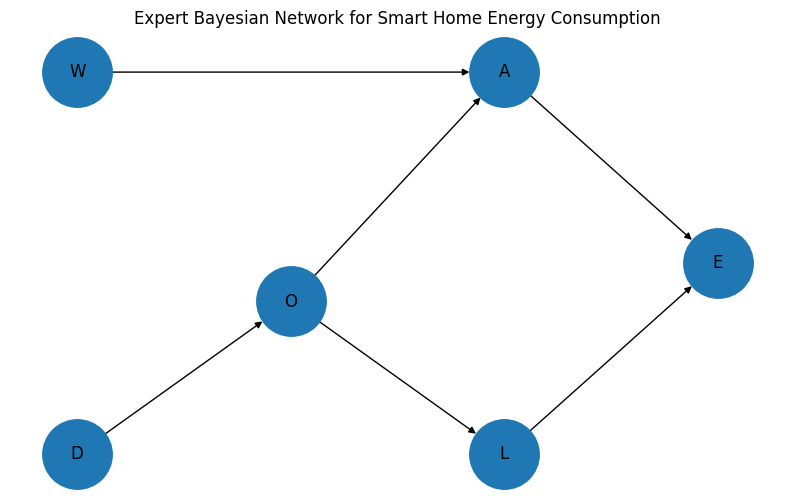

In [6]:
plt.figure(figsize=(10, 6))

pos = {
    "W": (0, 2),
    "D": (0, 0),
    "O": (2, 0.8),
    "A": (4, 2),
    "L": (4, 0),
    "E": (6, 1)
}

nx.draw_networkx(
    model,
    pos=pos,
    with_labels=True,
    node_size=2500,
    font_size=12,
    arrows=True
)

plt.title("Expert Bayesian Network for Smart Home Energy Consumption")
plt.axis("off")
plt.show()

### Probabilistic Inference

Probabilistic inference calculates the probability of a variable given observed evidence.

For example:

$$
P(E=\text{High}\mid W=\text{Hot})
$$

represents the probability of high energy consumption when the weather is hot.

We use variable elimination to compute the required probabilities from the expert-defined Bayesian Network.


In [7]:
infer = VariableElimination(model)

queries = {
    "Q1: P(E=High)": ("E", {}),
    "Q2: P(E=High | W=Hot)": ("E", {"W": "Hot"}),
    "Q3: P(E=High | D=Weekend)": ("E", {"D": "Weekend"}),
    "Q4: P(E=High | W=Cold, O=High)": (
        "E", {"W": "Cold", "O": "High"}
    ),
    "Q5: P(W=Hot | E=High)": ("W", {"E": "High"}),
    "Q6: P(A=On | E=High)": ("A", {"E": "High"}),
    "Q7: P(A=On | E=High, L=Heavy)": (
        "A", {"E": "High", "L": "Heavy"}
    )
}

results = {}

for name, (query_var, evidence) in queries.items():
    result = infer.query(
        variables=[query_var],
        evidence=evidence,
        show_progress=False
    )

    probability = result.get_value(**{
        query_var: (
            "High" if query_var in ["E", "W"]
            else "On"
        )
    }) if query_var != "W" else result.get_value(W="Hot")

    results[name] = float(probability)
    print(f"{name}: {probability:.6f}")

Q1: P(E=High): 0.580631
Q2: P(E=High | W=Hot): 0.706266
Q3: P(E=High | D=Weekend): 0.640199
Q4: P(E=High | W=Cold, O=High): 0.484250
Q5: P(W=Hot | E=High): 0.608188
Q6: P(A=On | E=High): 0.692867
Q7: P(A=On | E=High, L=Heavy): 0.649899


In [8]:
results_df = pd.DataFrame({
    "Query": list(results.keys()),
    "Probability": list(results.values())
})

display(results_df)

,Query,Probability
0,Q1: P(E=High),0.580631
1,Q2: P(E=High | W=Hot),0.706266
2,Q3: P(E=High | D=Weekend),0.640199
3,"Q4: P(E=High | W=Cold, O=High)",0.484250
4,Q5: P(W=Hot | E=High),0.608188
5,Q6: P(A=On | E=High),0.692867
6,"Q7: P(A=On | E=High, L=Heavy)",0.649899


### Explaining Away

Energy consumption depends on both air-conditioner usage and appliance load.

When high energy consumption is observed, both causes may initially become more likely. However, if we additionally learn that appliance load is heavy, this provides an alternative explanation for the high consumption.

Consequently, the probability that the air conditioner is on may decrease.

This phenomenon is known as **explaining away**. It occurs when two causes of a common effect become conditionally dependent after observing that effect.


In [9]:
q6 = results["Q6: P(A=On | E=High)"]
q7 = results["Q7: P(A=On | E=High, L=Heavy)"]

print(f"Q6 = {q6:.6f}")
print(f"Q7 = {q7:.6f}")
print(f"Change = {q7 - q6:.6f}")

if q7 < q6:
    print("The probability of AC being On decreases.")
elif q7 > q6:
    print("The probability of AC being On increases.")
else:
    print("The probability remains unchanged.")

Q6 = 0.692867
Q7 = 0.649899
Change = -0.042967
The probability of AC being On decreases.


### Manual Calculation of Q1

We need to calculate the probability of high energy consumption:

$$
P(E=\text{High})
$$

Using the law of total probability, we marginalize over all possible combinations of AC Usage ($A$) and Appliance Load ($L$):

$$
P(E=H)=\sum_{a,l}P(E=H\mid A=a,L=l)P(A=a,L=l)
$$

The expert CPT provides the following conditional probabilities:

$$
P(E=H\mid A=On,L=Heavy)=0.92
$$

$$
P(E=H\mid A=On,L=Light)=0.68
$$

$$
P(E=H\mid A=Off,L=Heavy)=0.55
$$

$$
P(E=H\mid A=Off,L=Light)=0.12
$$

After marginalizing over the parent variables, the joint probabilities of AC Usage and Appliance Load are:

| AC Usage ($A$) | Appliance Load ($L$) | $P(A,L)$ |
|---|---|---:|
| On | Heavy | 0.30087875 |
| On | Light | 0.18454625 |
| Off | Heavy | 0.27112125 |
| Off | Light | 0.24345375 |

Substituting these values into the law of total probability:

$$
\begin{aligned}
P(E=H)={}&(0.92)(0.30087875)\\
&+(0.68)(0.18454625)\\
&+(0.55)(0.27112125)\\
&+(0.12)(0.24345375)
\end{aligned}
$$

Therefore,

$$
\boxed{P(E=\text{High})=0.58063104}
$$

The manually calculated result is approximately $0.580631$. We compare this value with the result obtained through Bayesian Network inference to verify the calculation.

In [10]:
def joint_probability(assignment):
    probability = 1.0

    for variable in ["W", "D", "O", "A", "L", "E"]:
        cpd = model.get_cpds(variable)

        value = assignment[variable]
        parents = list(cpd.variables[1:])

        kwargs = {variable: value}
        kwargs.update({
            parent: assignment[parent]
            for parent in parents
        })

        probability *= float(cpd.get_value(**kwargs))

    return probability


states = {
    "W": ["Hot", "Mild", "Cold"],
    "D": ["Weekday", "Weekend"],
    "O": ["High", "Low"],
    "A": ["On", "Off"],
    "L": ["Heavy", "Light"],
    "E": ["High", "Low"]
}

q1_manual = 0.0

for values in itertools.product(*states.values()):
    assignment = dict(zip(states.keys(), values))

    if assignment["E"] == "High":
        q1_manual += joint_probability(assignment)

q1_inference = results["Q1: P(E=High)"]

print(f"Manual Q1:    {q1_manual:.8f}")
print(f"Inference Q1: {q1_inference:.8f}")
print("Match:", np.isclose(q1_manual, q1_inference))

Manual Q1:    0.58063104
Inference Q1: 0.58063104
Match: True


## Part B: Conditional Independence Analysis

Conditional independence describes whether knowing one variable provides additional information about another variable after some evidence is already known.

We analyze the following statements using d-separation:

1. $W \perp D$
2. $W \perp D \mid E$
3. $W \perp L \mid O$

### Statement 1: Weather and Day Type

Weather ($W$) and Day Type ($D$) are independent root nodes in the expert network. There is no path connecting them directly, and neither variable has a parent that connects it to the other.

Therefore, Weather and Day Type are independent:

$$
\boxed{W \perp D}
$$

### Statement 2: Weather and Day Type Given Energy Consumption

Weather can affect AC Usage, which affects Energy Consumption. Day Type affects Occupancy, which influences both AC Usage and Appliance Load. Both AC Usage and Appliance Load affect Energy Consumption.

Thus, the network contains the path:

$$
W \rightarrow A \rightarrow E \leftarrow L \leftarrow O \leftarrow D
$$

Energy Consumption ($E$) is a collider on this path. Without conditioning on the collider, the path is blocked. However, observing $E$ activates the path and can make Weather and Day Type dependent.

Therefore, conditional independence does not hold in general:

$$
\boxed{W \not\perp D \mid E}
$$

### Statement 3: Weather and Appliance Load Given Occupancy

We examine the paths between Weather ($W$) and Appliance Load ($L$).

The first relevant path is:

$$
W \rightarrow A \rightarrow E \leftarrow L
$$

Energy Consumption ($E$) is a collider on this path. Since neither $E$ nor its descendants are conditioned on, this path remains blocked.

The second relevant path is:

$$
W \rightarrow A \leftarrow O \rightarrow L
$$

AC Usage ($A$) is a collider on this path. Conditioning on Occupancy ($O$) does not activate this collider. Additionally, $O$ is a non-collider on this path, and conditioning on it blocks the path.

Therefore, all paths between Weather and Appliance Load are blocked when Occupancy is observed. Hence, Weather and Appliance Load are conditionally independent given Occupancy:

$$
\boxed{W \perp L \mid O}
$$

We verify these independence statements numerically by comparing the relevant probability distributions using Bayesian Network inference.

In [11]:
def get_distribution(variable, evidence=None):
    """Return the probability distribution of a variable."""
    result = infer.query(
        variables=[variable],
        evidence=evidence or {},
        show_progress=False
    )
    return result.values


independence_checks = []

p_w = get_distribution("W")
p_w_given_d = get_distribution("W", {"D": "Weekend"})

independence_checks.append({
    "Statement": "W ⟂ D",
    "Evidence": "D = Weekend",
    "Distribution 1": np.round(p_w, 6).tolist(),
    "Distribution 2": np.round(p_w_given_d, 6).tolist(),
    "Maximum Absolute Difference": float(
        np.max(np.abs(p_w - p_w_given_d))
    ),
    "Independent": bool(np.allclose(p_w, p_w_given_d))
})


p_w_given_e = get_distribution("W", {"E": "High"})
p_w_given_e_d = get_distribution(
    "W",
    {"E": "High", "D": "Weekend"}
)

independence_checks.append({
    "Statement": "W ⟂ D | E",
    "Evidence": "E = High; compare with D = Weekend",
    "Distribution 1": np.round(p_w_given_e, 6).tolist(),
    "Distribution 2": np.round(p_w_given_e_d, 6).tolist(),
    "Maximum Absolute Difference": float(
        np.max(np.abs(p_w_given_e - p_w_given_e_d))
    ),
    "Independent": bool(np.allclose(p_w_given_e, p_w_given_e_d))
})



for occupancy in ["High", "Low"]:
    p_w_given_o = get_distribution(
        "W",
        {"O": occupancy}
    )

    for load in ["Heavy", "Light"]:
        p_w_given_o_l = get_distribution(
            "W",
            {"O": occupancy, "L": load}
        )

        independence_checks.append({
            "Statement": "W ⟂ L | O",
            "Evidence": f"O = {occupancy}; L = {load}",
            "Distribution 1": np.round(p_w_given_o, 6).tolist(),
            "Distribution 2": np.round(p_w_given_o_l, 6).tolist(),
            "Maximum Absolute Difference": float(
                np.max(np.abs(p_w_given_o - p_w_given_o_l))
            ),
            "Independent": bool(
                np.allclose(p_w_given_o, p_w_given_o_l)
            )
        })


independence_results = pd.DataFrame(independence_checks)

display(independence_results)

print("\nInterpretation:")
print("- Statement 1 should be independent.")
print("- Statement 2 should not be independent.")
print("- Statement 3 should be independent for both occupancy values.")

,Statement,Evidence,Distribution 1,Distribution 2,Maximum Absolute Difference,Independent
0,W ⟂ D,D = Weekend,"[0.5, 0.3, 0.2]","[0.5, 0.3, 0.2]",0.000000,True
1,W ⟂ D | E,E = High; compare with D = Weekend,"[0.608188, 0.253992, 0.13782]","[0.599751, 0.260781, 0.139468]",0.008437,False
2,W ⟂ L | O,O = High; L = Heavy,"[0.5, 0.3, 0.2]","[0.5, 0.3, 0.2]",0.000000,True
3,W ⟂ L | O,O = High; L = Light,"[0.5, 0.3, 0.2]","[0.5, 0.3, 0.2]",0.000000,True
4,W ⟂ L | O,O = Low; L = Heavy,"[0.5, 0.3, 0.2]","[0.5, 0.3, 0.2]",0.000000,True
5,W ⟂ L | O,O = Low; L = Light,"[0.5, 0.3, 0.2]","[0.5, 0.3, 0.2]",0.000000,True



Interpretation:
- Statement 1 should be independent.
- Statement 2 should not be independent.
- Statement 3 should be independent for both occupancy values.


## Part C: Synthetic Data Generation

Synthetic datasets are generated using ancestral sampling.

The variables are sampled in topological order:

1. Weather
2. Day Type
3. Occupancy, given Day Type
4. AC Usage, given Weather and Occupancy
5. Appliance Load, given Occupancy
6. Energy Consumption, given AC Usage and Appliance Load

The random seed is fixed to 42 to ensure reproducibility.


In [12]:
rng = np.random.default_rng(SEED)

def sample_category(categories, probabilities):
    return rng.choice(categories, p=probabilities)


def generate_one_sample():
    W = sample_category(
        ["Hot", "Mild", "Cold"],
        [0.50, 0.30, 0.20]
    )

    D = sample_category(
        ["Weekday", "Weekend"],
        [0.70, 0.30]
    )

    p_occ_high = {
        "Weekday": 0.45,
        "Weekend": 0.80
    }[D]

    O = sample_category(
        ["High", "Low"],
        [p_occ_high, 1 - p_occ_high]
    )

    p_ac_on = {
        ("Hot", "High"): 0.90,
        ("Hot", "Low"): 0.60,
        ("Mild", "High"): 0.40,
        ("Mild", "Low"): 0.15,
        ("Cold", "High"): 0.10,
        ("Cold", "Low"): 0.05
    }[(W, O)]

    A = sample_category(
        ["On", "Off"],
        [p_ac_on, 1 - p_ac_on]
    )

    p_heavy = {
        "High": 0.75,
        "Low": 0.35
    }[O]

    L = sample_category(
        ["Heavy", "Light"],
        [p_heavy, 1 - p_heavy]
    )

    p_energy_high = {
        ("On", "Heavy"): 0.92,
        ("On", "Light"): 0.68,
        ("Off", "Heavy"): 0.55,
        ("Off", "Light"): 0.12
    }[(A, L)]

    E = sample_category(
        ["High", "Low"],
        [p_energy_high, 1 - p_energy_high]
    )

    return {
        "W": W,
        "D": D,
        "O": O,
        "A": A,
        "L": L,
        "E": E
    }


def generate_dataset(n):
    return pd.DataFrame(
        [generate_one_sample() for _ in range(n)]
    )


datasets = {
    500: generate_dataset(500),
    5000: generate_dataset(5000),
    20000: generate_dataset(20000)
}

print("Generated dataset sizes:")
for size, df in datasets.items():
    print(size, df.shape)

Generated dataset sizes:
500 (500, 6)
5000 (5000, 6)
20000 (20000, 6)


In [13]:
weather_summary = []

for size, df in datasets.items():
    frequencies = df["W"].value_counts(normalize=True)

    for weather in ["Hot", "Mild", "Cold"]:
        weather_summary.append({
            "Dataset Size": size,
            "Weather": weather,
            "Empirical Frequency": frequencies.get(weather, 0.0)
        })

weather_summary_df = pd.DataFrame(weather_summary)
display(weather_summary_df)

,Dataset Size,Weather,Empirical Frequency
0,500,Hot,0.5100
1,500,Mild,0.2860
2,500,Cold,0.2040
3,5000,Hot,0.4974
4,5000,Mild,0.3052
5,5000,Cold,0.1974
6,20000,Hot,0.4990
7,20000,Mild,0.3037
8,20000,Cold,0.1973


In [14]:
for size, df in datasets.items():
    print(f"\nDataset size: {size}")

    counts = pd.crosstab(
        df["W"],
        df["O"]
    ).reindex(
        index=["Hot", "Mild", "Cold"],
        columns=["High", "Low"],
        fill_value=0
    )

    display(counts)


Dataset size: 500


O,High,Low
W,,
Hot,155,100
Mild,75,68
Cold,51,51



Dataset size: 5000


O,High,Low
W,,
Hot,1393,1094
Mild,841,685
Cold,570,417



Dataset size: 20000


O,High,Low
W,,
Hot,5530,4450
Mild,3427,2647
Cold,2180,1766


## Part D: Learning from Data

We learn the parameters of the Bayesian Network from each synthetic dataset while keeping the network structure fixed.

### Maximum Likelihood Estimation

MLE estimates probabilities using observed frequencies in the dataset.

For example:

$$
\hat{P}(A=On\mid W,O)
=
\frac{N(A=On,W,O)}{N(W,O)}
$$

If a parent configuration never appears in the dataset, MLE cannot estimate its conditional distribution reliably.

### Bayesian Estimation

Bayesian parameter estimation incorporates a prior distribution to smooth the estimates.

We use the BDeu prior with equivalent sample size:

$$
ESS=10
$$

The learned CPTs will be compared against the expert CPTs, followed by the same seven inference queries.


In [15]:
from pgmpy.estimators import (
    BayesianEstimator,
    MaximumLikelihoodEstimator
)
from pgmpy.models import DiscreteBayesianNetwork

structure = [
    ("D", "O"),
    ("W", "A"),
    ("O", "A"),
    ("O", "L"),
    ("A", "E"),
    ("L", "E")
]

state_names = {
    "W": ["Hot", "Mild", "Cold"],
    "D": ["Weekday", "Weekend"],
    "O": ["High", "Low"],
    "A": ["On", "Off"],
    "L": ["Heavy", "Light"],
    "E": ["High", "Low"]
}


def learn_model(data, estimator_type):
    learned = DiscreteBayesianNetwork(structure)

    estimator = estimator_type(
        learned,
        data,
        state_names=state_names
    )

    if estimator_type == MaximumLikelihoodEstimator:
        cpds = estimator.get_parameters()
    else:
        cpds = estimator.get_parameters(
            prior_type="BDeu",
            equivalent_sample_size=10
        )

    learned.add_cpds(*cpds)

    return learned

In [16]:
learned_models = {}

for size, df in datasets.items():

    print(f"\nTraining models for {size} samples...")

    learned_models[(size, "MLE")] = learn_model(
        df,
        MaximumLikelihoodEstimator
    )

    learned_models[(size, "Bayesian")] = learn_model(
        df,
        BayesianEstimator
    )

    print(
        "MLE valid:",
        learned_models[(size, "MLE")].check_model()
    )

    print(
        "Bayesian valid:",
        learned_models[(size, "Bayesian")].check_model()
    )

print("\nAll models trained successfully!")


Training models for 500 samples...
MLE valid: True
Bayesian valid: True

Training models for 5000 samples...


/tmp/ipykernel_2618/2373623881.py:29: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = estimator_type(
/tmp/ipykernel_2618/2373623881.py:29: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = estimator_type(
/tmp/ipykernel_2618/2373623881.py:29: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = estimator_type(
/tmp/ipykernel_2618/2373623881.py:29: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = estimator_type(


MLE valid: True
Bayesian valid: True

Training models for 20000 samples...


/tmp/ipykernel_2618/2373623881.py:29: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = estimator_type(
/tmp/ipykernel_2618/2373623881.py:29: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = estimator_type(


MLE valid: True
Bayesian valid: True

All models trained successfully!


In [17]:

ac_states = ["On", "Off"]
weather_states = ["Hot", "Mild", "Cold"]
occupancy_states = ["High", "Low"]

parent_configurations = [
    f"W={weather}, O={occupancy}"
    for weather in weather_states
    for occupancy in occupancy_states
]


expert_ac_df = pd.DataFrame(
    cpd_A.get_values(),
    index=ac_states,
    columns=parent_configurations
)

print("EXPERT AC USAGE CPT")
display(expert_ac_df.round(6))


for size in [500, 5000, 20000]:
    for estimator in ["MLE", "Bayesian"]:

        learned = learned_models[(size, estimator)]
        learned_ac = learned.get_cpds("A")

        learned_ac_df = pd.DataFrame(
            learned_ac.get_values(),
            index=ac_states,
            columns=parent_configurations
        )

        print(
            f"\nLEARNED AC USAGE CPT | "
            f"Dataset Size = {size} | Estimator = {estimator}"
        )

        display(learned_ac_df.round(6))

EXPERT AC USAGE CPT


,"W=Hot, O=High","W=Hot, O=Low","W=Mild, O=High","W=Mild, O=Low","W=Cold, O=High","W=Cold, O=Low"
On,0.9,0.6,0.4,0.15,0.1,0.05
Off,0.1,0.4,0.6,0.85,0.9,0.95



LEARNED AC USAGE CPT | Dataset Size = 500 | Estimator = MLE


,"W=Hot, O=High","W=Hot, O=Low","W=Mild, O=High","W=Mild, O=Low","W=Cold, O=High","W=Cold, O=Low"
On,0.851613,0.36,0.098039,0.66,0.176471,0.019608
Off,0.148387,0.64,0.901961,0.34,0.823529,0.980392



LEARNED AC USAGE CPT | Dataset Size = 500 | Estimator = Bayesian


,"W=Hot, O=High","W=Hot, O=Low","W=Mild, O=High","W=Mild, O=Low","W=Cold, O=High","W=Cold, O=Low"
On,0.847872,0.363043,0.110759,0.657377,0.184211,0.03481
Off,0.152128,0.636957,0.889241,0.342623,0.815789,0.96519


... (4 outputs left out)


LEARNED AC USAGE CPT | Dataset Size = 20000 | Estimator = MLE


,"W=Hot, O=High","W=Hot, O=Low","W=Mild, O=High","W=Mild, O=Low","W=Cold, O=High","W=Cold, O=Low"
On,0.906872,0.393347,0.109174,0.594607,0.151114,0.053228
Off,0.093128,0.606653,0.890826,0.405393,0.848886,0.946772



LEARNED AC USAGE CPT | Dataset Size = 20000 | Estimator = Bayesian


,"W=Hot, O=High","W=Hot, O=Low","W=Mild, O=High","W=Mild, O=Low","W=Cold, O=High","W=Cold, O=Low"
On,0.906749,0.393399,0.109473,0.594571,0.151334,0.053649
Off,0.093251,0.606601,0.890527,0.405429,0.848666,0.946351


## Part E: Comparative Analysis

The expert model is treated as the reference model.

For each dataset size, we compare its seven inference probabilities against those obtained from the MLE and Bayesian learned models.

The absolute difference is:

$$
\text{Absolute Difference}
=
|P_{\text{Expert}}-P_{\text{Learned}}|
$$

The mean absolute difference is:

$$
MAD=
\frac{1}{7}
\sum_{i=1}^{7}
|P_{\text{Expert},i}-P_{\text{Learned},i}|
$$

A smaller mean absolute difference indicates that the learned model's inference results are closer to those of the expert model.


In [18]:
def calculate_queries(model_to_test):
    inference = VariableElimination(model_to_test)

    query_specs = [
        ("Q1", "E", {}, "High"),
        ("Q2", "E", {"W": "Hot"}, "High"),
        ("Q3", "E", {"D": "Weekend"}, "High"),
        ("Q4", "E", {"W": "Cold", "O": "High"}, "High"),
        ("Q5", "W", {"E": "High"}, "Hot"),
        ("Q6", "A", {"E": "High"}, "On"),
        ("Q7", "A", {"E": "High", "L": "Heavy"}, "On")
    ]

    output = {}

    for name, variable, evidence, state in query_specs:
        factor = inference.query(
            variables=[variable],
            evidence=evidence,
            show_progress=False
        )

        output[name] = float(
            factor.get_value(**{variable: state})
        )

    return output


expert_results = calculate_queries(model)

comparison_records = []

for size in [500, 5000, 20000]:
    mle_results = calculate_queries(
        learned_models[(size, "MLE")]
    )

    bayesian_results = calculate_queries(
        learned_models[(size, "Bayesian")]
    )

    for query in ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"]:
        comparison_records.append({
            "Dataset Size": size,
            "Query": query,
            "Expert": expert_results[query],
            "MLE": mle_results[query],
            "Bayesian": bayesian_results[query],
            "MLE Absolute Difference": abs(
                expert_results[query] - mle_results[query]
            ),
            "Bayesian Absolute Difference": abs(
                expert_results[query] - bayesian_results[query]
            )
        })

comparison_df = pd.DataFrame(comparison_records)

display(comparison_df.round(6))

,Dataset Size,Query,Expert,MLE,Bayesian,MLE Absolute Difference,Bayesian Absolute Difference
0,500,Q1,0.580631,0.556977,0.555939,0.023654,0.024692
1,500,Q2,0.706266,0.704969,0.699108,0.001297,0.007158
2,500,Q3,0.640198,0.609242,0.604562,0.030956,0.035636
3,500,Q4,0.484250,0.420305,0.426789,0.063945,0.057461
4,500,Q5,0.608188,0.645510,0.636983,0.037322,0.028795
5,500,Q6,0.692867,0.727981,0.723610,0.035114,0.030743
6,500,Q7,0.649899,0.658365,0.655952,0.008466,0.006052
7,5000,Q1,0.580631,0.581455,0.581298,0.000824,0.000667
8,5000,Q2,0.706266,0.703291,0.702733,0.002974,0.003533
9,5000,Q3,0.640198,0.642807,0.642187,0.002609,0.001989


,MLE Absolute Difference,Bayesian Absolute Difference
Dataset Size,,
500,0.028679,0.027220
5000,0.003622,0.003754
20000,0.001929,0.001992


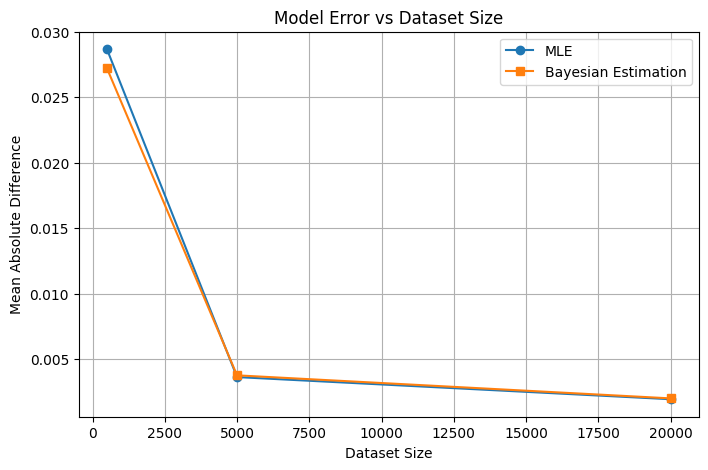

In [19]:
mad_df = comparison_df.groupby("Dataset Size")[
    ["MLE Absolute Difference", "Bayesian Absolute Difference"]
].mean()

display(mad_df)

plt.figure(figsize=(8, 5))

plt.plot(
    mad_df.index,
    mad_df["MLE Absolute Difference"],
    marker="o",
    label="MLE"
)

plt.plot(
    mad_df.index,
    mad_df["Bayesian Absolute Difference"],
    marker="s",
    label="Bayesian Estimation"
)

plt.xlabel("Dataset Size")
plt.ylabel("Mean Absolute Difference")
plt.title("Model Error vs Dataset Size")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
small_data = comparison_df[
    comparison_df["Dataset Size"] == 500
].copy()

small_data["Maximum Error"] = small_data[
    ["MLE Absolute Difference", "Bayesian Absolute Difference"]
].max(axis=1)

largest_error_row = small_data.loc[
    small_data["Maximum Error"].idxmax()
]

print("Query with largest error for 500 samples:")
display(largest_error_row)

Query with largest error for 500 samples:


,3
Dataset Size,500
Query,Q4
Expert,0.48425
MLE,0.420305
Bayesian,0.426789
MLE Absolute Difference,0.063945
Bayesian Absolute Difference,0.057461
Maximum Error,0.063945


### Discussion

The experiment compares the expert Bayesian Network with models learned using Maximum Likelihood Estimation (MLE) and Bayesian Estimation with a BDeu prior and an equivalent sample size of 10. The comparison uses datasets containing 500, 5,000 and 20,000 samples.

The mean absolute differences (MADs) obtained are:

| Dataset Size | MLE MAD | Bayesian MAD |
|---:|---:|---:|
| 500 | 0.028679 | 0.027220 |
| 5,000 | 0.003622 | 0.003754 |
| 20,000 | 0.001929 | 0.001992 |

As the dataset size increases, the errors generally decrease for both estimators. This indicates that larger datasets allow the learned models to reproduce the inference results of the expert model more closely.

For 500 samples, Bayesian estimation performs slightly better than MLE, with a MAD of 0.027220 compared with 0.028679. Bayesian estimation incorporates a BDeu prior, which smooths probability estimates and can reduce the effect of sparse observations in smaller datasets.

For 5,000 and 20,000 samples, MLE performs slightly better in this experiment. With more observations, empirical frequency estimates become more reliable, reducing the advantage provided by prior smoothing.

For the dataset containing 500 samples, Q4, $P(E=\text{High}\mid W=\text{Cold},O=\text{High})$, has the largest error among the queries considered. This query depends on a particular combination of evidence, and limited observations for relevant parent configurations can make the learned probabilities less accurate. Bayesian smoothing reduces the error for this query compared with MLE in the experiment.

Overall, Bayesian estimation performs slightly better on the smallest dataset, whereas MLE performs slightly better on the two larger datasets. Neither estimator is universally superior; their relative performance depends on the dataset size and the evidence used in each query.